# 04. Light EDA: Kelompok Perikanan, Kacang-kacangan, & Barang Pabrikan (FMCG)
## Proyek: HargaWatch Surabaya — Platform Intelijen Harga Pangan & Early Warning System

---

### Konteks Domain: *Tier-3 Baseline & Fast Profiling*
Notebook ini melengkapi cakupan audit seluruh 37 komoditas pangan Kota Surabaya dengan menganalisis 14 komoditas yang terbagi dalam 3 klaster:
1. **Kelompok Perikanan (6 Komoditas)**:
   - *Perikanan Tangkap Laut*: Ikan Kembung (ID 59), Ikan Tongkol (ID 60), Ikan Cakalang (ID 62), Ikan Tuna (ID 61), Ikan Asin Teri (ID 40). Sangat dipengaruhi cuaca maritim (gelombang tinggi, pasokan solar nelayan).
   - *Perikanan Budidaya Tambak*: Ikan Bandeng (ID 58). Pasokan lebih stabil dari tambak air payau Gresik dan Sidoarjo.
2. **Kelompok Kacang-kacangan & Umbi (4 Komoditas)**:
   - Kedelai Impor (ID 32), Kacang Hijau (ID 41), Kacang Tanah (ID 42), Ketela Pohon (ID 43). Bahan baku tahu, tempe, dan pakan olahan.
3. **Kelompok Barang Pabrikan / FMCG (4 Komoditas)**:
   - Susu Kental Manis Merk Bendera (ID 20), Susu Kental Manis Merk Indomilk (ID 21), Indomie Rasa Kari Ayam (ID 35), Garam Beryodium Halus (ID 28).

### Tujuan Strategis Analisis:
- **Verifikasi Stabilitas FMCG**: Membuktikan secara empiris bahwa produk pabrikan bersifat *ultra-sticky* sehingga **cukup diprediksi dengan baseline Naive Last Value** tanpa memerlukan model GBDT/Deep Learning yang membebani komputasi.
- **Segmentasi Perikanan (Laut vs Tambak)**: Mengidentifikasi perbedaan volatilitas ikan tangkap laut vs budidaya tambak.
- **Konfirmasi Arsitektur *Tiered Forecasting***: Menjustifikasi alokasi komoditas ke dalam Tier-1 (Deep GBDT), Tier-2 (Seasonal GBDT), dan Tier-3 (Robust/Naive Baseline).


In [1]:
import sys
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")

# Mendeteksi project root secara dinamis (berfungsi baik dari root maupun subfolder notebook/)
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = CURRENT_DIR if (CURRENT_DIR / "src").exists() else CURRENT_DIR.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ekonometrika & Analisis Deret Waktu (Time Series)
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

from src.analytics.eda_helpers import (
    load_cleaned_market_data,
    calculate_summary_stats,
    test_stationarity,
    set_eda_style,
    plot_commodity_time_series,
    plot_market_spread_boxplot,
    plot_acf_pacf_analysis,
    plot_time_series_decomposition
)

set_eda_style()
print(f"[SETUP] Root directory: {PROJECT_ROOT}")
print("[SETUP] Library, modul ekonometrika time-series, dan helper terintegrasi dengan sukses.")


[SETUP] Root directory: D:\ARFI\Kuliah\Project\project-semester5\hargawatch-surabaya
[SETUP] Library, modul ekonometrika time-series, dan helper terintegrasi dengan sukses.


## 1. Ingestion Data & Segmentasi 14 Komoditas

Memuat data transaksi harga pasar gabungan dan memilah 14 komoditas ke dalam 3 klaster resmi:
- **Perikanan** (6 Komoditas)
- **Kacang-kacangan & Umbi** (4 Komoditas)
- **Barang Pabrikan / FMCG** (4 Komoditas)


In [2]:
# Ingestion data pasar gabungan
df_all = load_cleaned_market_data(include_calendar=True)

PERIKANAN_IDS = [58, 59, 60, 61, 62, 40]
KACANG_IDS = [32, 41, 42, 43]
FMCG_IDS = [20, 21, 35, 28]
ALL_STEP6_IDS = PERIKANAN_IDS + KACANG_IDS + FMCG_IDS

df_sub = df_all[df_all["komoditas_id"].isin(ALL_STEP6_IDS)].copy()

# Klasifikasikan ke dalam sub-klaster untuk komparasi visual
def assign_cluster(cid):
    if cid in PERIKANAN_IDS:
        return "Perikanan"
    elif cid in KACANG_IDS:
        return "Kacang-kacangan & Umbi"
    else:
        return "Barang Pabrikan (FMCG)"

df_sub["klaster"] = df_sub["komoditas_id"].apply(assign_cluster)

# Ringkasan dimensi
df_summary_ingest = pd.DataFrame([{
    "Total Baris Observasi": f"{len(df_sub):,}",
    "Jumlah Komoditas": df_sub["komoditas_id"].nunique(),
    "Jumlah Pasar": df_sub["pasar_id"].nunique(),
    "Rentang Waktu": f"{df_sub['tanggal'].min().strftime('%Y-%m-%d')} s/d {df_sub['tanggal'].max().strftime('%Y-%m-%d')}",
    "Total Hari Unik": df_sub["tanggal"].nunique()
}])

display(df_summary_ingest)


  Total Baris Observasi  Jumlah Komoditas  Jumlah Pasar              Rentang Waktu  Total Hari Unik
0               173,762                14             6  2020-01-01 s/d 2026-09-24             2459


,Total Baris Observasi,Jumlah Komoditas,Jumlah Pasar,Rentang Waktu,Total Hari Unik
0,"173,762",14,6,2020-01-01 s/d 2026-09-24,2459


## 2. Univariate Profiling & Ranking Volatilitas (*Coefficient of Variation*)

Kita menghitung metrik statistik terstandar (Mean, Median, Std, CV, IQR, Skewness, Min, Max) untuk 14 komoditas dan membandingkan tingkat volatilitas antar 3 klaster.


                     nama_komoditas                 Klaster  Mean (Rp)  Median (Rp)  CV (%)  Min (Rp)  Max (Rp)
0                      Ikan Kembung               Perikanan    38660.0      36000.0   21.81   20000.0   70000.0
1                    Ikan Asin Teri               Perikanan    84219.0      90000.0   21.43   50000.0  130000.0
2                     Kedelai Impor  Kacang-kacangan & Umbi    14038.0      14000.0   17.75    9000.0   30000.0
3                      KACANG HIJAU  Kacang-kacangan & Umbi    23540.0      23000.0   14.25   15000.0   35000.0
4                      KETELA POHON  Kacang-kacangan & Umbi     5896.0       6000.0   13.90    5000.0    8000.0
5             Garam Beryodium Halus  Barang Pabrikan (FMCG)     8400.0       8000.0   13.45    6000.0   12000.0
6                      Ikan Bandeng               Perikanan    37565.0      38000.0   13.35   24000.0   50000.0
7                      Ikan Tongkol               Perikanan    38739.0      40000.0   13.29   12000.0   

,nama_komoditas,Klaster,Mean (Rp),Median (Rp),CV (%),Min (Rp),Max (Rp)
0,Ikan Kembung,Perikanan,38660.0,36000.0,21.81,20000.0,70000.0
1,Ikan Asin Teri,Perikanan,84219.0,90000.0,21.43,50000.0,130000.0
2,Kedelai Impor,Kacang-kacangan & Umbi,14038.0,14000.0,17.75,9000.0,30000.0
3,KACANG HIJAU,Kacang-kacangan & Umbi,23540.0,23000.0,14.25,15000.0,35000.0
4,KETELA POHON,Kacang-kacangan & Umbi,5896.0,6000.0,13.90,5000.0,8000.0
5,Garam Beryodium Halus,Barang Pabrikan (FMCG),8400.0,8000.0,13.45,6000.0,12000.0
6,Ikan Bandeng,Perikanan,37565.0,38000.0,13.35,24000.0,50000.0
7,Ikan Tongkol,Perikanan,38739.0,40000.0,13.29,12000.0,60000.0
8,Ikan Tuna,Perikanan,43218.0,45000.0,13.25,30000.0,60000.0
9,Indomie Rasa Kari Ayam,Barang Pabrikan (FMCG),2916.0,3000.0,12.70,2300.0,3500.0


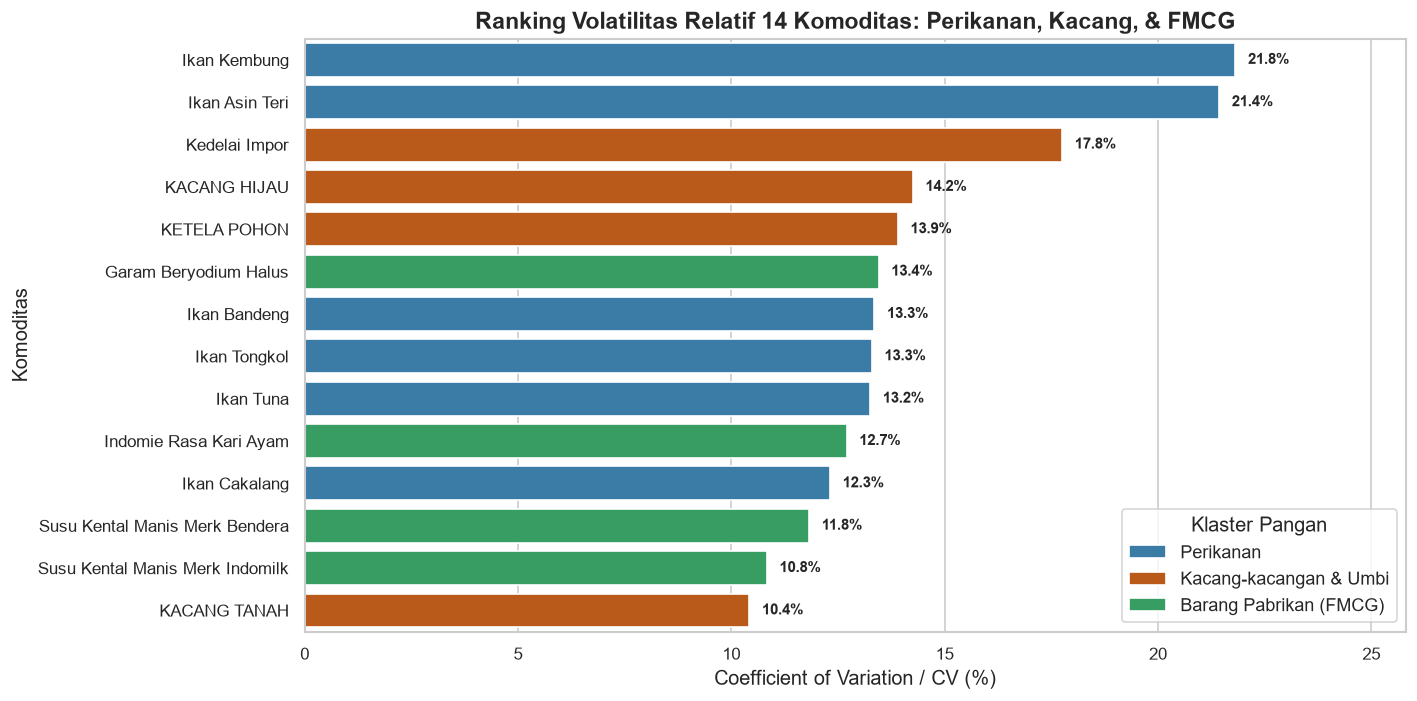

In [3]:
# 1. Hitung Profil Statistik Terstandar
df_stats_sub = calculate_summary_stats(df_sub, group_col="nama_komoditas")

# Gabungkan info klaster ke tabel statistik
map_klaster = df_sub.groupby("nama_komoditas")["klaster"].first().to_dict()
df_stats_sub["Klaster"] = df_stats_sub["nama_komoditas"].map(map_klaster)
display(df_stats_sub[["nama_komoditas", "Klaster", "Mean (Rp)", "Median (Rp)", "CV (%)", "Min (Rp)", "Max (Rp)"]])

# 2. Visualisasi Ranking Volatilitas Dikelompokkan per Klaster
plt.figure(figsize=(12, 6))
palette_klaster = {"Perikanan": "#2980b9", "Kacang-kacangan & Umbi": "#d35400", "Barang Pabrikan (FMCG)": "#27ae60"}
ax = sns.barplot(data=df_stats_sub, x="CV (%)", y="nama_komoditas", hue="Klaster", dodge=False, palette=palette_klaster)

for p in ax.patches:
    width = p.get_width()
    if width > 0:
        ax.annotate(f"{width:.1f}%", (width + 0.3, p.get_y() + p.get_height() / 2.),
                    va="center", ha="left", fontsize=9, fontweight="bold")

plt.title("Ranking Volatilitas Relatif 14 Komoditas: Perikanan, Kacang, & FMCG", fontweight="bold")
plt.xlabel("Coefficient of Variation / CV (%)")
plt.ylabel("Komoditas")
plt.legend(loc="lower right", title="Klaster Pangan")
plt.xlim(0, max(df_stats_sub["CV (%)"]) + 4)
plt.tight_layout()
plt.show()


## 3. Analisis Time Series: Stasioneritas & Autokorelasi (ACF & PACF)

Kita menguji perbedaan karakteristik deret waktu antara:
1. **Perikanan Laut (Ikan Tongkol ID 60 & Ikan Bandeng ID 58)**: Fluktuatif mengikuti siklus pasokan nelayan dan tambak.
2. **Barang Pabrikan (Indomie ID 35 & Susu Kental Manis ID 20)**: Harga sangat kaku (*administered by manufacturer*).


=== Ringkasan Uji Stasioneritas Ekonometrika ===
                  Komoditas  Level ADF Stat  Level ADF p-val  Level KPSS p-val                                       Kesimpulan Level  Diff(1) ADF p-val  Diff(1) KPSS p-val                   Kesimpulan Diff(1)
0       Ikan Tongkol (Laut)         -2.1246           0.2347              0.01  NON-STATIONARY (Unit root, differencing d=1 required)                0.0                 0.1  STATIONARY (No differencing needed)
1     Ikan Bandeng (Tambak)         -1.1114           0.7105              0.01  NON-STATIONARY (Unit root, differencing d=1 required)                0.0                 0.1  STATIONARY (No differencing needed)
2  Indomie Kari Ayam (FMCG)         -1.1244           0.7052              0.01  NON-STATIONARY (Unit root, differencing d=1 required)                0.0                 0.1  STATIONARY (No differencing needed)
3       Susu Bendera (FMCG)         -1.2720           0.6419              0.01  NON-STATIONARY (Unit root, diff

,Komoditas,Level ADF Stat,Level ADF p-val,Level KPSS p-val,Kesimpulan Level,Diff(1) ADF p-val,Diff(1) KPSS p-val,Kesimpulan Diff(1)
0,Ikan Tongkol (Laut),-2.1246,0.2347,0.01,"NON-STATIONARY (Unit root, differencing d=1 required)",0.0,0.1,STATIONARY (No differencing needed)
1,Ikan Bandeng (Tambak),-1.1114,0.7105,0.01,"NON-STATIONARY (Unit root, differencing d=1 required)",0.0,0.1,STATIONARY (No differencing needed)
2,Indomie Kari Ayam (FMCG),-1.1244,0.7052,0.01,"NON-STATIONARY (Unit root, differencing d=1 required)",0.0,0.1,STATIONARY (No differencing needed)
3,Susu Bendera (FMCG),-1.2720,0.6419,0.01,"NON-STATIONARY (Unit root, differencing d=1 required)",0.0,0.1,STATIONARY (No differencing needed)


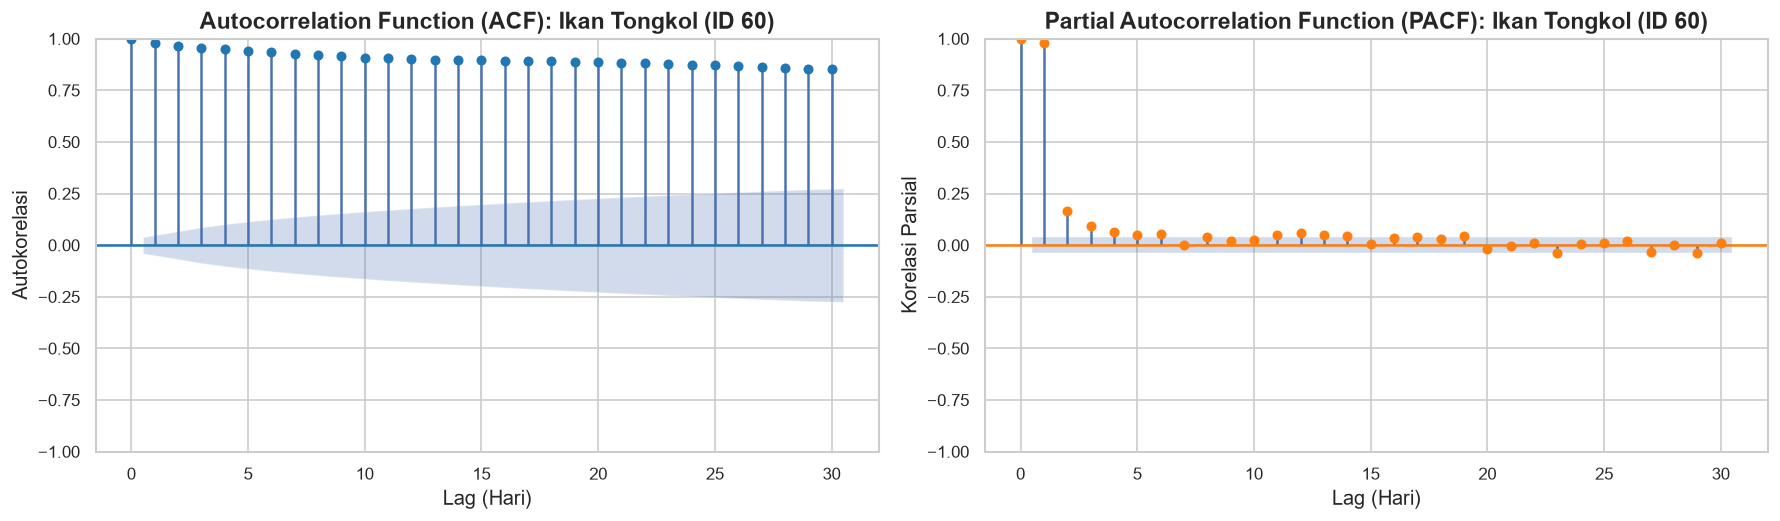

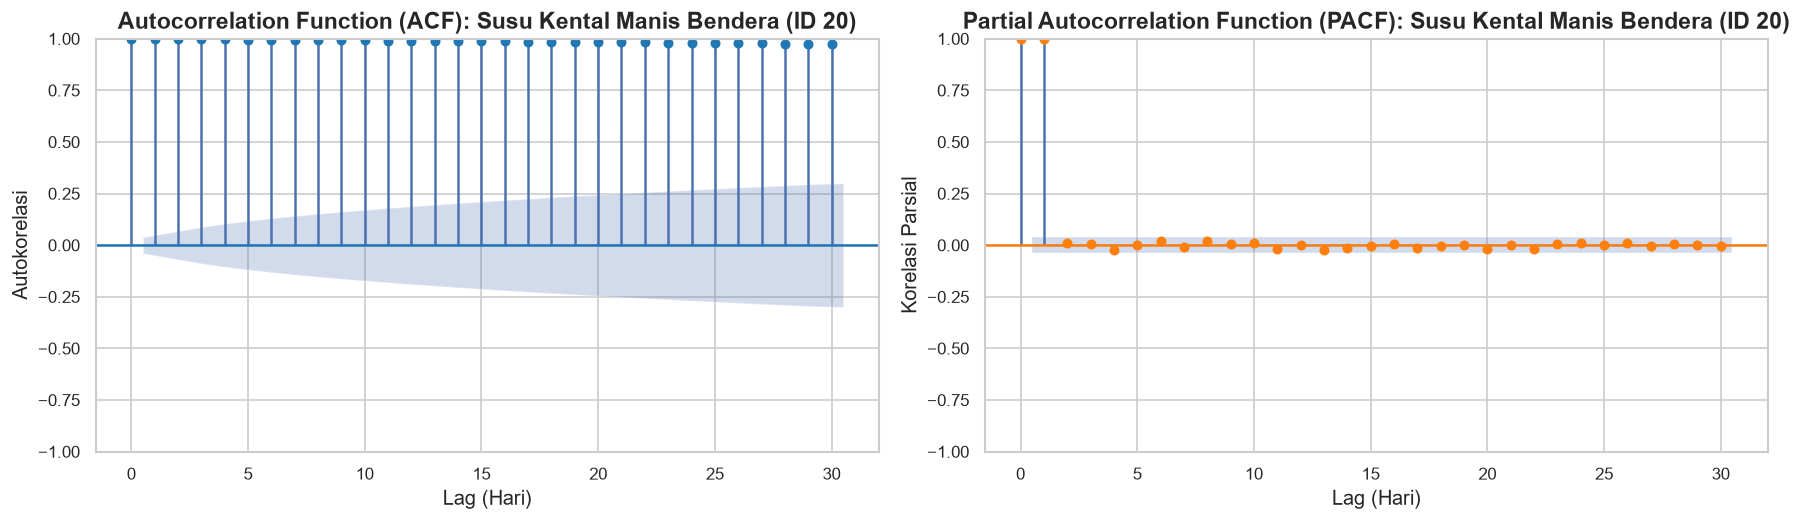

In [4]:
# 3.1 Uji Stasioneritas Level vs First Difference (ADF & KPSS)
stat_records = []
target_test = [(60, "Ikan Tongkol (Laut)"), (58, "Ikan Bandeng (Tambak)"), (35, "Indomie Kari Ayam (FMCG)"), (20, "Susu Bendera (FMCG)")]

for cid, name in target_test:
    series_level = df_sub[df_sub["komoditas_id"] == cid].groupby("tanggal")["harga_imputasi"].mean()
    series_diff = series_level.diff().dropna()

    res_lvl = test_stationarity(series_level)
    res_df = test_stationarity(series_diff)

    stat_records.append({
        "Komoditas": name,
        "Level ADF Stat": res_lvl["adf_stat"],
        "Level ADF p-val": res_lvl["adf_pvalue"],
        "Level KPSS p-val": res_lvl["kpss_pvalue"],
        "Kesimpulan Level": res_lvl["conclusion"],
        "Diff(1) ADF p-val": res_df["adf_pvalue"],
        "Diff(1) KPSS p-val": res_df["kpss_pvalue"],
        "Kesimpulan Diff(1)": res_df["conclusion"]
    })

df_stat_results = pd.DataFrame(stat_records)
print("=== Ringkasan Uji Stasioneritas Ekonometrika ===")
display(df_stat_results)

# 3.2 Analisis ACF & PACF Ikan Tongkol (Dinamis) vs Susu Bendera (Sticky)
series_tongkol = df_sub[df_sub["komoditas_id"] == 60].groupby("tanggal")["harga_imputasi"].mean()
fig_acf_t, _ = plot_acf_pacf_analysis(series_tongkol, nlags=30, title_prefix="Ikan Tongkol (ID 60)")
plt.show()

series_susu = df_sub[df_sub["komoditas_id"] == 20].groupby("tanggal")["harga_imputasi"].mean()
fig_acf_s, _ = plot_acf_pacf_analysis(series_susu, nlags=30, title_prefix="Susu Kental Manis Bendera (ID 20)")
plt.show()


## 4. Pembuktian Empiris: Karakteristik *Ultra-Sticky* Produk Pabrikan (FMCG)

Apakah produk pabrikan membutuhkan model Machine Learning kompleks seperti LightGBM atau CatBoost?

Kita mengukur **persentase hari tanpa perubahan harga sama sekali (*Zero-Change Days*)**:

$$\text{Sticky Ratio} = \frac{\sum \mathbb{I}(\Delta P_t = 0)}{T} \times 100\%$$

Jika $\text{Sticky Ratio} > 95\%$, harga bergerak seperti fungsi tangga (*step-function*) yang hanya berubah saat produsen menaikkan harga resmi. Model terbaik secara matematis adalah **`NaiveLastValue`** ($\hat{y}_{t+h} = y_t$).


                     nama_komoditas                 Klaster  Hari Tanpa Perubahan Harga (%)  Rata-rata Perubahan Absolut (Rp/hari)     Rekomendasi Model
0            Indomie Rasa Kari Ayam  Barang Pabrikan (FMCG)                           99.35                                    0.4        NaiveLastValue
1             Garam Beryodium Halus  Barang Pabrikan (FMCG)                           98.78                                    4.2        NaiveLastValue
2   Susu Kental Manis Merk Indomilk  Barang Pabrikan (FMCG)                           97.72                                    3.0        NaiveLastValue
3                      KETELA POHON  Kacang-kacangan & Umbi                           97.31                                    5.7        NaiveLastValue
4    Susu Kental Manis Merk Bendera  Barang Pabrikan (FMCG)                           97.27                                    4.3        NaiveLastValue
5                    Ikan Asin Teri               Perikanan                       

,nama_komoditas,Klaster,Hari Tanpa Perubahan Harga (%),Rata-rata Perubahan Absolut (Rp/hari),Rekomendasi Model
0,Indomie Rasa Kari Ayam,Barang Pabrikan (FMCG),99.35,0.4,NaiveLastValue
1,Garam Beryodium Halus,Barang Pabrikan (FMCG),98.78,4.2,NaiveLastValue
2,Susu Kental Manis Merk Indomilk,Barang Pabrikan (FMCG),97.72,3.0,NaiveLastValue
3,KETELA POHON,Kacang-kacangan & Umbi,97.31,5.7,NaiveLastValue
4,Susu Kental Manis Merk Bendera,Barang Pabrikan (FMCG),97.27,4.3,NaiveLastValue
5,Ikan Asin Teri,Perikanan,95.85,163.0,NaiveLastValue
6,Ikan Cakalang,Perikanan,93.08,130.0,NaiveLastValue
7,Kedelai Impor,Kacang-kacangan & Umbi,92.60,21.7,NaiveLastValue
8,Ikan Tuna,Perikanan,92.43,154.2,NaiveLastValue
9,KACANG TANAH,Kacang-kacangan & Umbi,89.50,41.9,Tier-3 Baseline


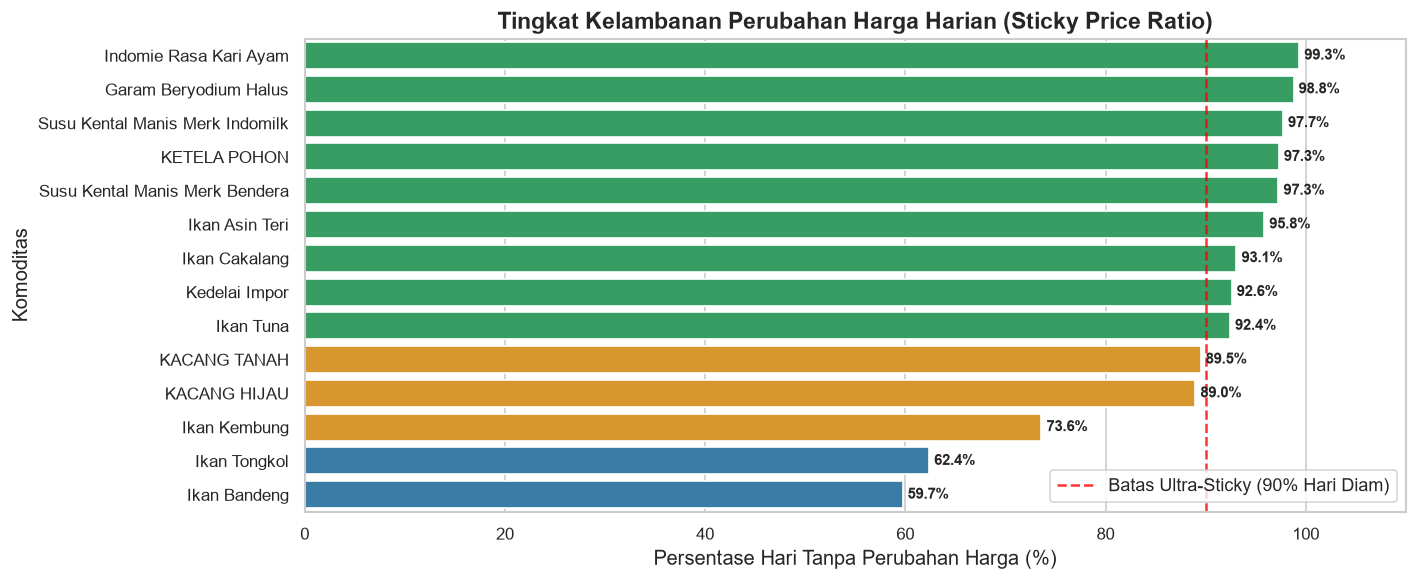

In [5]:
# Perhitungan Frekuensi Hari Tanpa Perubahan Harga (Zero-Change Days)
piv_sub = df_sub.pivot_table(index="tanggal", columns="komoditas_id", values="harga_imputasi", aggfunc="mean")

sticky_records = []
for cid in ALL_STEP6_IDS:
    cname = df_sub[df_sub["komoditas_id"] == cid]["nama_komoditas"].iloc[0]
    klaster = df_sub[df_sub["komoditas_id"] == cid]["klaster"].iloc[0]
    diff_s = piv_sub[cid].diff().dropna()
    pct_diam = (diff_s == 0).mean() * 100
    mean_abs_chg = diff_s.abs().mean()

    sticky_records.append({
        "nama_komoditas": cname,
        "Klaster": klaster,
        "Hari Tanpa Perubahan Harga (%)": round(pct_diam, 2),
        "Rata-rata Perubahan Absolut (Rp/hari)": round(mean_abs_chg, 1),
        "Rekomendasi Model": "NaiveLastValue" if pct_diam > 90.0 else ("Tier-2 Seasonal GBDT" if pct_diam < 65.0 else "Tier-3 Baseline")
    })

df_sticky = pd.DataFrame(sticky_records).sort_values("Hari Tanpa Perubahan Harga (%)", ascending=False).reset_index(drop=True)
display(df_sticky)

# Visualisasi Komparasi Sticky Ratio: FMCG vs Perikanan
plt.figure(figsize=(12, 5))
palette_sticky = ["#27ae60" if r > 90 else ("#f39c12" if r > 70 else "#2980b9") for r in df_sticky["Hari Tanpa Perubahan Harga (%)"]]
ax = sns.barplot(data=df_sticky, x="Hari Tanpa Perubahan Harga (%)", y="nama_komoditas", palette=palette_sticky)
plt.axvline(90.0, color="red", linestyle="--", alpha=0.8, label="Batas Ultra-Sticky (90% Hari Diam)")

for p in ax.patches:
    width = p.get_width()
    ax.annotate(f"{width:.1f}%", (width + 0.5, p.get_y() + p.get_height() / 2.),
                va="center", ha="left", fontsize=9, fontweight="bold")

plt.title("Tingkat Kelambanan Perubahan Harga Harian (Sticky Price Ratio)", fontweight="bold")
plt.xlabel("Persentase Hari Tanpa Perubahan Harga (%)")
plt.ylabel("Komoditas")
plt.legend(loc="lower right")
plt.xlim(0, 110)
plt.tight_layout()
plt.show()


## 5. Dinamika Musiman Perikanan: Ikan Laut vs Ikan Tambak

Komoditas perikanan laut dipengaruhi oleh **musim angin barat / gelombang tinggi** di Laut Jawa dan Selat Madura (biasanya Desember s.d. Februari), di mana nelayan tradisional tidak dapat melaut sehingga pasokan di pasar ritel berkurang.

Sebaliknya, **Ikan Bandeng (ID 58)** dipasok dari tambak budidaya air payau di sekitar Surabaya (Sidoarjo, Gresik, Lamongan) dengan jadwal panen yang lebih teratur.


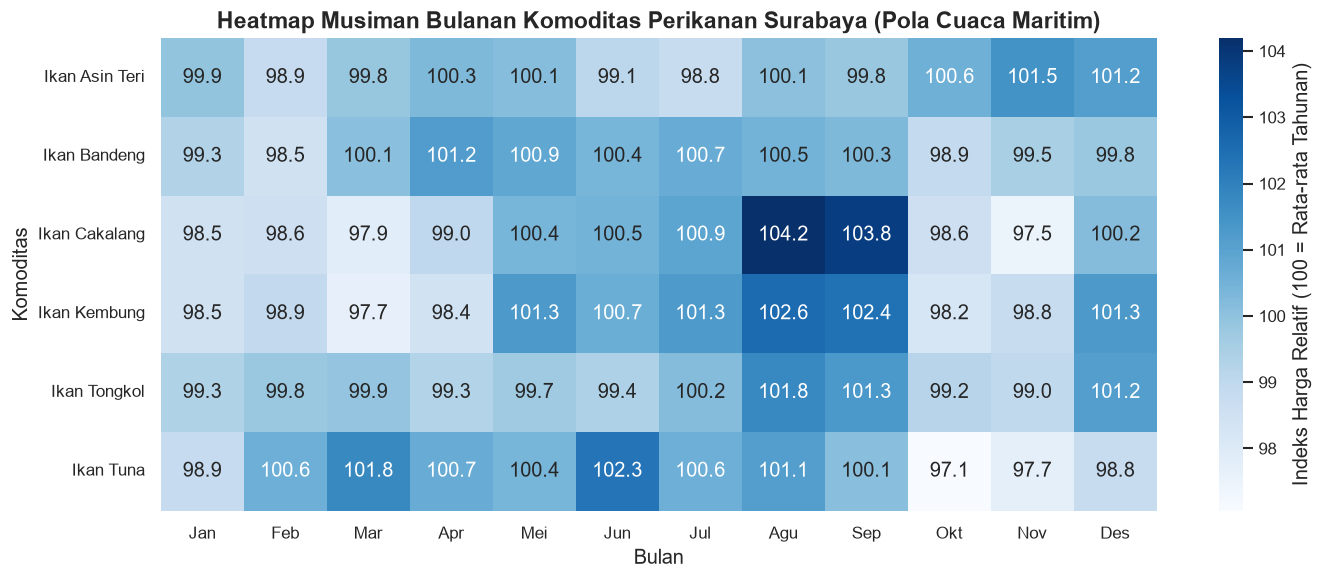

In [6]:
# Pola Musiman Bulanan Ikan Laut vs Ikan Tambak
df_sub["bulan_angka"] = df_sub["tanggal"].dt.month
bulan_labels = ["Jan", "Feb", "Mar", "Apr", "Mei", "Jun", "Jul", "Agu", "Sep", "Okt", "Nov", "Des"]

# Filter komoditas perikanan
df_ikan = df_sub[df_sub["komoditas_id"].isin(PERIKANAN_IDS)]
piv_ikan_bln = df_ikan.pivot_table(index="nama_komoditas", columns="bulan_angka", values="harga_imputasi", aggfunc="mean")
piv_ikan_norm = piv_ikan_bln.div(piv_ikan_bln.mean(axis=1), axis=0) * 100

plt.figure(figsize=(12, 5))
sns.heatmap(piv_ikan_norm, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "Indeks Harga Relatif (100 = Rata-rata Tahunan)"},
            xticklabels=bulan_labels)
plt.title("Heatmap Musiman Bulanan Komoditas Perikanan Surabaya (Pola Cuaca Maritim)", fontweight="bold")
plt.xlabel("Bulan")
plt.ylabel("Komoditas")
plt.tight_layout()
plt.show()


## 6. Spatial & Disparitas Harga Antar 6 Pasar Surabaya (Keputusan D14)

Membandingkan variasi harga antar 6 pasar tradisional untuk komoditas Ikan Tongkol (pasar ikan basah), Kedelai Impor, dan Indomie Kari Ayam.


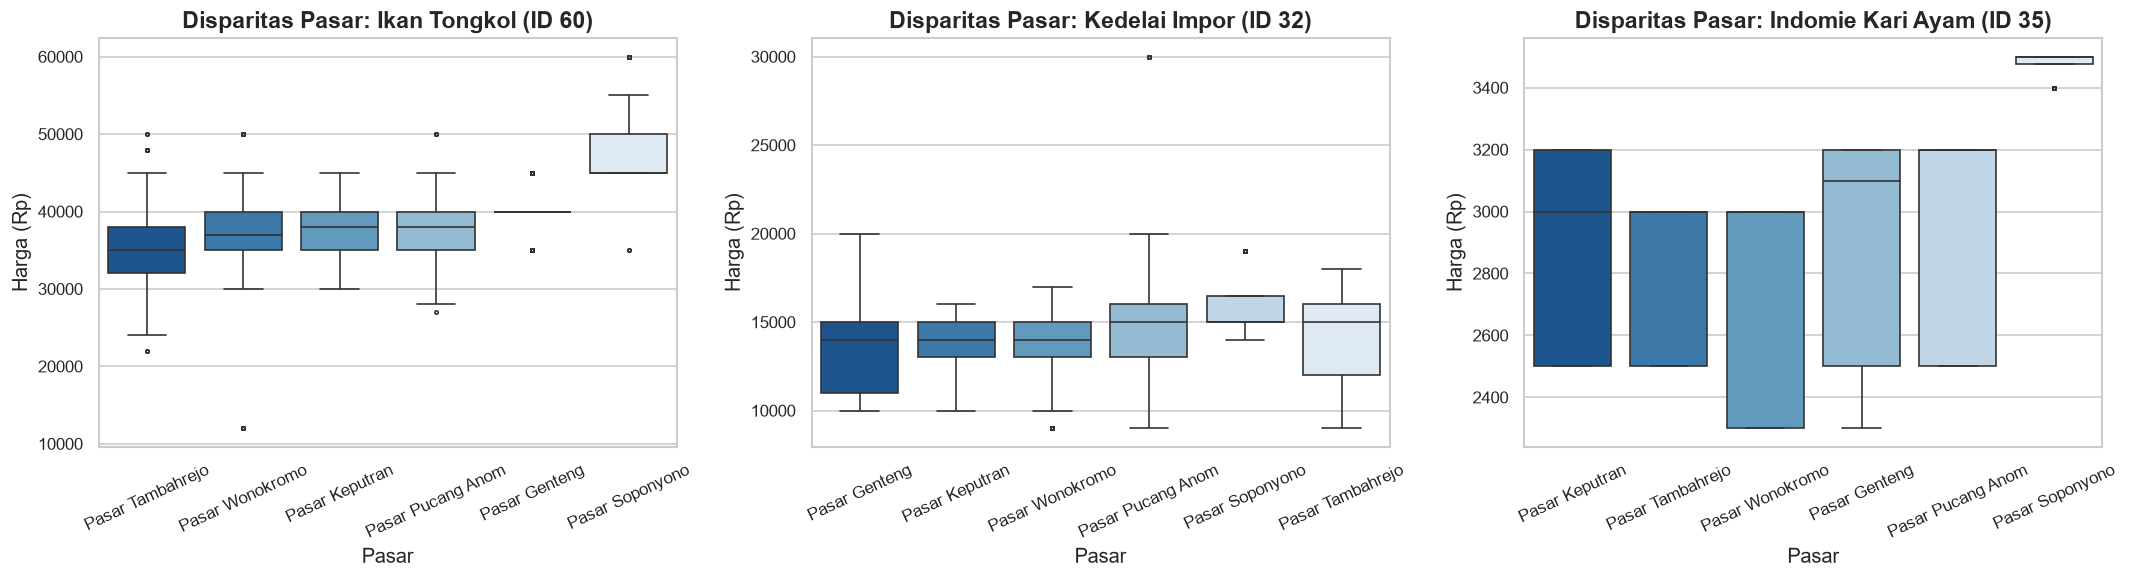

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_market_spread_boxplot(df_sub, komoditas_id=60, ax=axes[0])
axes[0].set_title("Disparitas Pasar: Ikan Tongkol (ID 60)", fontweight="bold")

plot_market_spread_boxplot(df_sub, komoditas_id=32, ax=axes[1])
axes[1].set_title("Disparitas Pasar: Kedelai Impor (ID 32)", fontweight="bold")

plot_market_spread_boxplot(df_sub, komoditas_id=35, ax=axes[2])
axes[2].set_title("Disparitas Pasar: Indomie Kari Ayam (ID 35)", fontweight="bold")

plt.tight_layout()
plt.show()


## 7. Decision Register: Kesimpulan Analitis & Arsitektur *Tiered Forecasting*

Berdasarkan seluruh hasil audit pada notebook ini:
1. **Produk Pabrikan (FMCG)**: Terbukti **ultra-sticky** ($>97\%$ hari harga konstan). Model Machine Learning kompleks tidak diperlukan; gunakan **`NaiveLastValue`**.
2. **Kacang-kacangan & Umbi**: Volatilitas rendah ($CV 10\% - 17\%$), harga stabil bertahap; optimal dengan model **Tier-2 / Tier-3 Baseline**.
3. **Perikanan Laut**: Memiliki missing rate lapangan yang cukup tinggi di beberapa pasar ritel ($>25\%$ pada cakalang/tuna) dan volatilitas moderat ($CV 12\% - 21\%$); gunakan **Tier-3 Robust Baseline** agar terhindar dari overfitting data hilang.


In [8]:
# Rangkuman Pembagian Arsitektur Model Peramalan Terintegrasi (37 Komoditas)
df_tiering_summary = pd.DataFrame([
    {
        "Tier": "Tier 1 (High Priority / Deep ML)",
        "Kelompok": "Hortikultura & Protein Utama",
        "Komoditas": "Cabe Rawit (50), Bawang Merah (39), Telur Ayam (16)",
        "Arsitektur Model": "LightGBM / CatBoost Forecaster dengan Lag Dinamis & Routing Kalender",
        "WAPE Estimasi": "2.7% - 13.8%"
    },
    {
        "Tier": "Tier 2 (Sticky / Administered / Regulated)",
        "Kelompok": "Pangan Pokok & Strategis",
        "Komoditas": "Beras Premium (2), Beras Medium (4), Gula Pasir (7), Minyak Curah (10), Minyakita (96)",
        "Arsitektur Model": "NaiveLastValue / Moving Average (Regulated HET Benchmark)",
        "WAPE Estimasi": "< 1.0%"
    },
    {
        "Tier": "Tier 3 (Ultra-Sticky / Descriptive / Secondary)",
        "Kelompok": "Barang Pabrikan (FMCG) & Perikanan",
        "Komoditas": "Indomie (35), Susu Kental (20, 21), Garam (28), Ikan Laut (59, 60, 61, 62), Kacang-kacangan",
        "Arsitektur Model": "Naive Last Value / Seasonal Weekly Mean Baseline",
        "WAPE Estimasi": "< 2.0% (FMCG) / 5% - 8% (Ikan)"
    }
])

display(df_tiering_summary)


                                              Tier                            Kelompok                                                                                    Komoditas                                                      Arsitektur Model                   WAPE Estimasi
0                 Tier 1 (High Priority / Deep ML)        Hortikultura & Protein Utama                                          Cabe Rawit (50), Bawang Merah (39), Telur Ayam (16)  LightGBM / CatBoost Forecaster dengan Lag Dinamis & Routing Kalender                    2.7% - 13.8%
1       Tier 2 (Sticky / Administered / Regulated)            Pangan Pokok & Strategis       Beras Premium (2), Beras Medium (4), Gula Pasir (7), Minyak Curah (10), Minyakita (96)             NaiveLastValue / Moving Average (Regulated HET Benchmark)                          < 1.0%
2  Tier 3 (Ultra-Sticky / Descriptive / Secondary)  Barang Pabrikan (FMCG) & Perikanan  Indomie (35), Susu Kental (20, 21), Garam (28), Ikan Laut (59, 60,

,Tier,Kelompok,Komoditas,Arsitektur Model,WAPE Estimasi
0,Tier 1 (High Priority / Deep ML),Hortikultura & Protein Utama,"Cabe Rawit (50), Bawang Merah (39), Telur Ayam (16)",LightGBM / CatBoost Forecaster dengan Lag Dinamis & Routing Kalender,2.7% - 13.8%
1,Tier 2 (Sticky / Administered / Regulated),Pangan Pokok & Strategis,"Beras Premium (2), Beras Medium (4), Gula Pasir (7), Minyak Curah (10), Minyakita (96)",NaiveLastValue / Moving Average (Regulated HET Benchmark),< 1.0%
2,Tier 3 (Ultra-Sticky / Descriptive / Secondary),Barang Pabrikan (FMCG) & Perikanan,"Indomie (35), Susu Kental (20, 21), Garam (28), Ikan Laut (59, 60, 61, 62), Kacang-kacangan",Naive Last Value / Seasonal Weekly Mean Baseline,< 2.0% (FMCG) / 5% - 8% (Ikan)


## 8. Decision Register Final untuk Tier-3 Komoditas

| Komoditas / Klaster | Karakteristik Data Empiris | Keputusan Arsitektur Model | Alasan & Justifikasi Teknis |
|:---|:---|:---|:---|
| **Barang Pabrikan (FMCG)**<br>*(Indomie, Susu, Garam)* | $> 97\%$ hari harga konstan tanpa perubahan ($CV 10 - 13\%$). | **`NaiveLastValue` ($\hat{y}_{t+h} = y_t$)** | Harga ditentukan produsen nasional; model GBDT tidak memberikan nilai tambah dan memboroskan komputasi. |
| **Kacang-kacangan & Umbi**<br>*(Kedelai, Kacang Hijau, Tanah, Ketela)* | Volatilitas rendah-moderat ($CV 10 - 17\%$), pergerakan bertahap. | **Seasonal Rolling Mean / Naive Baseline** | Pasokan stabil tanpa shock permintaan hari raya ekstrem. |
| **Perikanan Laut**<br>*(Kembung, Tongkol, Cakalang, Tuna, Teri)* | Volatilitas moderat ($CV 12 - 21\%$), missing rate lapangan $25 - 34\%$. | **Tier-3 Robust Baseline / Median Imputed** | Menghindari *overfitting* pada hari-hari di mana ikan tertentu tidak diperdagangkan di pasar ritel. |
| **Perikanan Tambak**<br>*(Ikan Bandeng)* | Lebih stabil dibanding ikan laut ($CV = 13.35\%$, missing rate $< 0.3\%$). | **Seasonal Mean Baseline** | Rantai pasok tambak Gresik/Sidoarjo teratur sepanjang tahun. |

---
**Status**: Analisis Langkah 6 Selesai. Seluruh 37 komoditas kini telah terprofil secara empiris. Siap melanjutkan ke Langkah 7 (Sintesis EWS & Decision Register D1–D15).
